In [ ]:
!pip install torch torchvision elpv-dataset scikit-learn opencv-python matplotlib

In [1]:
import torch
import torch.nn as nn
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import numpy as np
from elpv_dataset.utils import load_dataset
import os

# 1. Carregamento dos dados (necessário para o test_loader)
images, proba, types = load_dataset()
X = np.stack([images, images, images], axis=-1)
X = X.transpose(0, 3, 1, 2).astype(np.float32)
y = proba.astype(np.float32)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

class ELPVDataset(Dataset):
    def __init__(self, images, labels, augment=False):
        self.images = torch.tensor(images, dtype=torch.float32)
        if self.images.max() > 1.0:
            self.images = self.images / 255.0
        self.labels = torch.tensor(labels, dtype=torch.float32).unsqueeze(1)
        self.augment = augment
    def __len__(self):
        return len(self.images)
    def __getitem__(self, idx):
        return self.images[idx], self.labels[idx]

test_loader = DataLoader(ELPVDataset(X_test, y_test, augment=False), batch_size=32, shuffle=False, pin_memory=True)

# 2. Configurar dispositivo e criar arquitetura
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = models.resnet18(weights=None)
num_ftrs = model.fc.in_features
model.fc = nn.Sequential(
    nn.Linear(num_ftrs, 128),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(128, 1),
    nn.Sigmoid()
)

# 3. Carregar os pesos do treinamento anterior
caminho_modelo = os.path.join('../models', 'resnet18_elpv.pth')
#model.load_state_dict(torch.load('resnet18_elpv.pth', map_location=device))
model.load_state_dict(torch.load(caminho_modelo))
model = model.to(device)
model.eval()

# 4. Obter y_true e y_pred rodando o modelo no conjunto de teste
y_true_list, y_pred_list = [], []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        y_true_list.extend(targets.cpu().numpy())
        y_pred_list.extend(outputs.cpu().numpy())

y_true = np.array(y_true_list).flatten()
y_pred = np.array(y_pred_list).flatten()

print("Modelo carregado com sucesso!")

Modelo carregado com sucesso!


In [2]:
import torch.nn.functional as F

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        
        self.target_layer.register_forward_hook(self.save_activation)
        self.target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output.detach()

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate_heatmap(self, input_tensor):
        self.model.eval()
        output = self.model(input_tensor)
        pred_val = output.item()
        
        self.model.zero_grad()
        output.backward()
        
        weights = torch.mean(self.gradients, dim=[2, 3], keepdim=True)
        weighted_activations = weights * self.activations
        heatmap = torch.sum(weighted_activations, dim=1).squeeze(0)
        
        heatmap = torch.relu(heatmap).cpu().numpy()
        if np.max(heatmap) > 0:
            heatmap /= np.max(heatmap)
            
        return heatmap, pred_val

# Instanciando o Grad-CAM apontando para a última camada convolucional da ResNet18
grad_cam = GradCAM(model=model, target_layer=model.layer4[-1])


--- Métricas de Classificação (Threshold = 0.5) ---
Acurácia : 88.58%
Precisão : 0.8761
Recall   : 0.7615
F1-Score : 0.8148


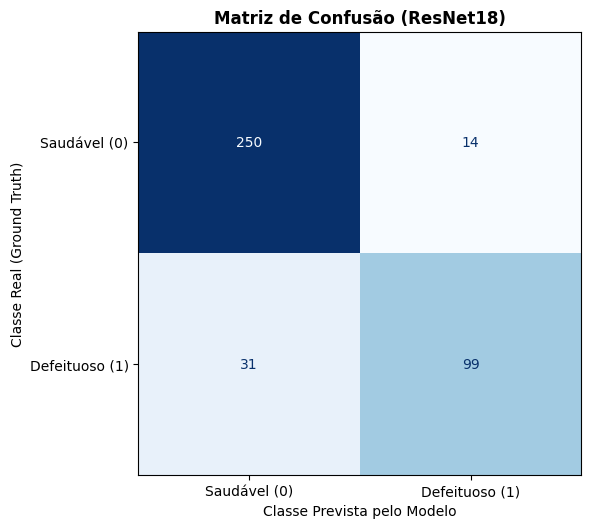

In [3]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import os

# 1. Binarizando as probabilidades reais e preditas (Threshold = 0.5)
# Se a probabilidade for >= 0.5, consideramos Defeituosa (1), senão Saudável (0)
threshold = 0.5
y_true_bin = (y_true >= threshold).astype(int)
y_pred_bin = (y_pred >= threshold).astype(int)

# 2. Calculando as métricas de classificação
accuracy = accuracy_score(y_true_bin, y_pred_bin)
precision, recall, f1, _ = precision_recall_fscore_support(y_true_bin, y_pred_bin, average='binary')

print(f"\n--- Métricas de Classificação (Threshold = {threshold}) ---")
print(f"Acurácia : {accuracy * 100:.2f}%")
print(f"Precisão : {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

# 3. Gerando a Matriz de Confusão
cm = confusion_matrix(y_true_bin, y_pred_bin)

plots_path = os.path.join('../plots', 'matriz_confusão.png')

plt.figure(figsize=(6, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Saudável (0)', 'Defeituoso (1)'])
disp.plot(cmap=plt.cm.Blues, values_format='d', ax=plt.gca(), colorbar=False)
plt.title(f'Matriz de Confusão (ResNet18)', fontsize=12, fontweight='bold')
plt.xlabel('Classe Prevista pelo Modelo', fontsize=10)
plt.ylabel('Classe Real (Ground Truth)', fontsize=10)
plt.grid(False) # Remove linhas de grade para melhor visualização da matriz
plt.savefig(plots_path, format='png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

Extraindo características do espaço latente (camada 2048D)...
Dimensões da matriz de características: (394, 512)
Executando o t-SNE (isso pode levar alguns segundos)...


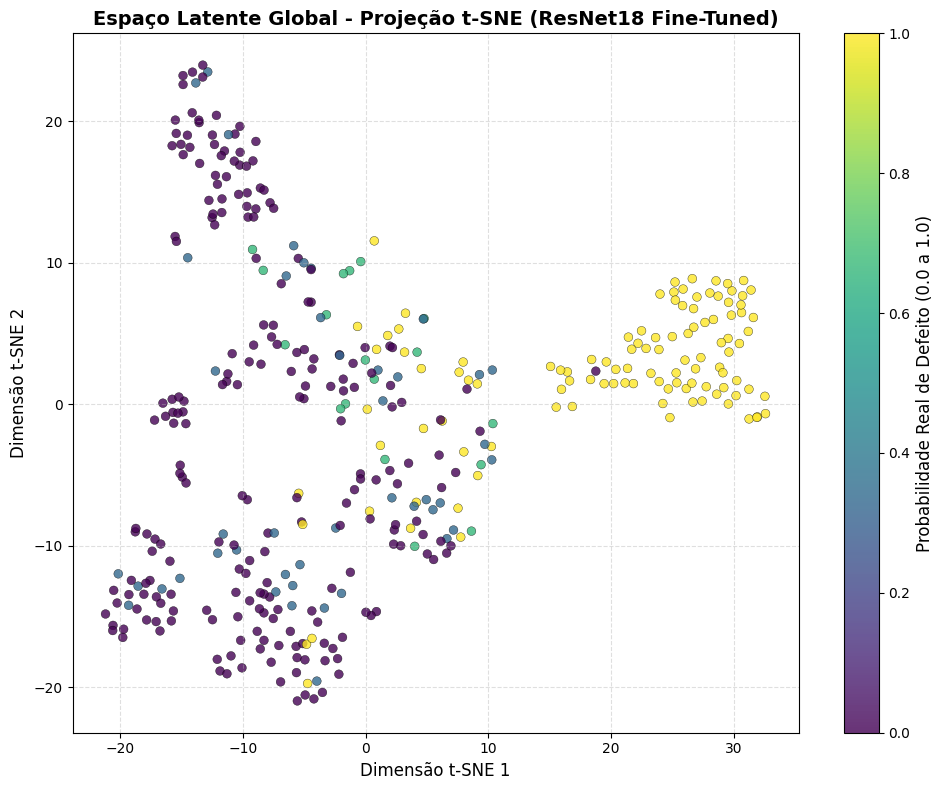

In [4]:
from sklearn.manifold import TSNE
import torch
import numpy as np
import matplotlib.pyplot as plt
import os

print("Extraindo características do espaço latente (camada 2048D)...")

plots_path = os.path.join('../plots', 'projecao_t-sne.png')

# Criando um extrator de características removendo a camada final 'fc' da ResNet18
feature_extractor = nn.Sequential(*(list(model.children())[:-1]))
feature_extractor.to(device)
feature_extractor.eval()

features_list = []
labels_list = []

# Extraindo features de todo o conjunto de teste
with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        feats = feature_extractor(inputs)
        feats = feats.view(feats.size(0), -1)
        
        features_list.append(feats.cpu().numpy())
        labels_list.append(targets.numpy())

X_features = np.concatenate(features_list, axis=0)
y_labels = np.concatenate(labels_list, axis=0).flatten()

print(f"Dimensões da matriz de características: {X_features.shape}")

# Aplicando o algoritmo t-SNE (usando max_iter em vez de n_iter)
print("Executando o t-SNE (isso pode levar alguns segundos)...")
tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000, init='pca', learning_rate='auto')
X_embedded = tsne.fit_transform(X_features)

# Geração do Gráfico de Dispersão Global
plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    X_embedded[:, 0], 
    X_embedded[:, 1], 
    c=y_labels, 
    cmap='viridis', 
    alpha=0.8, 
    s=40,
    edgecolors='k',
    linewidths=0.3
)

cbar = plt.colorbar(scatter)
cbar.set_label('Probabilidade Real de Defeito (0.0 a 1.0)', fontsize=12)
plt.title('Espaço Latente Global - Projeção t-SNE (ResNet18 Fine-Tuned)', fontsize=14, fontweight='bold')
plt.xlabel('Dimensão t-SNE 1', fontsize=12)
plt.ylabel('Dimensão t-SNE 2', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.4)

plt.savefig(plots_path, format='png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

Resultados de Fidelidade Explicativa para a amostra:
-> AUC Deleção (Quanto menor, melhor): 0.2981
-> AUC Inserção (Quanto maior, melhor): 0.3020


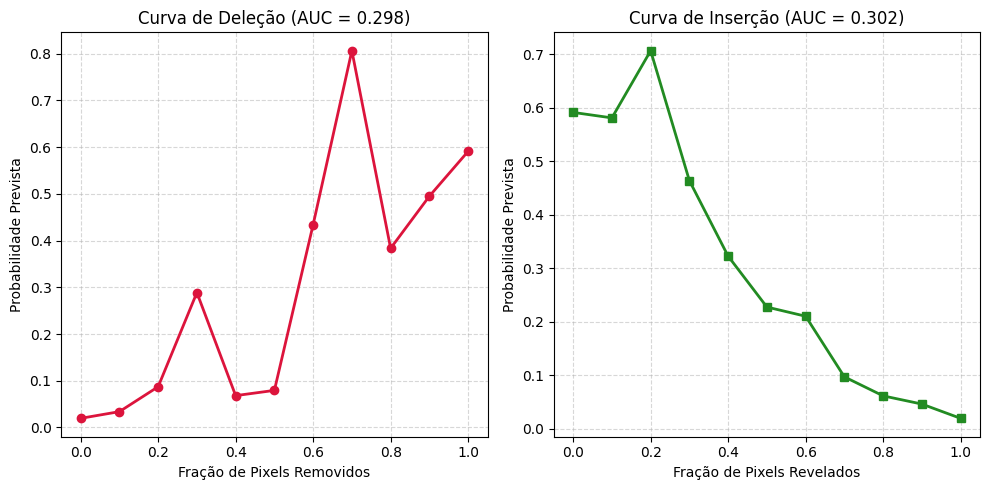

In [5]:
import numpy as np
import torch
import cv2
import matplotlib.pyplot as plt
from sklearn.metrics import auc
import os

plots_path = os.path.join('../plots', 'curva_auc.png')

def evaluate_faithfulness(model, grad_cam, image_tensor, device, steps=10):
    model.eval()
    img_tensor_dev = image_tensor.to(device)
    
    with torch.no_grad():
        orig_pred = model(img_tensor_dev).item()
        
    # Gera o heatmap do Grad-CAM
    heatmap, _ = grad_cam.generate_heatmap(img_tensor_dev)
    H, W = image_tensor.shape[2], image_tensor.shape[3]
    heatmap_resized = cv2.resize(heatmap, (W, H))
    
    # Índices dos pixels ordenados por importância decrescente
    flat_indices = np.argsort(heatmap_resized.flatten())[::-1]
    num_pixels = heatmap_resized.size
    step_size = num_pixels // steps
    
    img_np = image_tensor.cpu().numpy()[0] # Shape [C, H, W]
    C = img_np.shape[0]
    
    deletion_preds = [orig_pred]
    baseline = np.zeros_like(img_np)
    
    # Inserção começa com imagem preta
    with torch.no_grad():
        base_tensor = torch.tensor(baseline, dtype=torch.float32).unsqueeze(0).to(device)
        insertion_preds = [model(base_tensor).item()]
        
    for i in range(1, steps + 1):
        k = min(i * step_size, num_pixels)
        idx_to_change = flat_indices[:k]
        
        # Deleção: Mascarando os pixels importantes
        del_img = img_np.copy()
        for c in range(C):
            channel_flat = del_img[c].flatten()
            channel_flat[idx_to_change] = 0.0
            del_img[c] = channel_flat.reshape(H, W)
            
        with torch.no_grad():
            t_del = torch.tensor(del_img, dtype=torch.float32).unsqueeze(0).to(device)
            deletion_preds.append(model(t_del).item())
            
        # Inserção: Revelando apenas os pixels importantes
        ins_img = baseline.copy()
        for c in range(C):
            channel_flat_ins = ins_img[c].flatten()
            orig_flat = img_np[c].flatten()
            channel_flat_ins[idx_to_change] = orig_flat[idx_to_change]
            ins_img[c] = channel_flat_ins.reshape(H, W)
            
        with torch.no_grad():
            t_ins = torch.tensor(ins_img, dtype=torch.float32).unsqueeze(0).to(device)
            insertion_preds.append(model(t_ins).item())
            
    x_axis = np.linspace(0, 1, steps + 1)
    del_auc = auc(x_axis, deletion_preds)
    ins_auc = auc(x_axis, insertion_preds)
    
    return del_auc, ins_auc, deletion_preds, insertion_preds

# Executando a avaliação em algumas amostras do test_loader
model.eval()
target_layer = model.layer4[-1]
grad_cam = GradCAM(model, target_layer)

data_iter = iter(test_loader)
images_batch, labels_batch = next(data_iter)

# Vamos testar na primeira imagem do lote
sample_img = images_batch[0].unsqueeze(0)
del_auc, ins_auc, del_curve, ins_curve = evaluate_faithfulness(model, grad_cam, sample_img, device, steps=10)

print(f"Resultados de Fidelidade Explicativa para a amostra:")
print(f"-> AUC Deleção (Quanto menor, melhor): {del_auc:.4f}")
print(f"-> AUC Inserção (Quanto maior, melhor): {ins_auc:.4f}")

# Plotando as Curvas de Deleção e Inserção
x_steps = np.linspace(0, 1, len(del_curve))
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.plot(x_steps, del_curve, marker='o', color='crimson', lw=2)
plt.title(f'Curva de Deleção (AUC = {del_auc:.3f})')
plt.xlabel('Fração de Pixels Removidos')
plt.ylabel('Probabilidade Prevista')
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1, 2, 2)
plt.plot(x_steps, ins_curve, marker='s', color='forestgreen', lw=2)
plt.title(f'Curva de Inserção (AUC = {ins_auc:.3f})')
plt.xlabel('Fração de Pixels Revelados')
plt.ylabel('Probabilidade Prevista')
plt.grid(True, linestyle='--', alpha=0.5)

plt.savefig(plots_path, format='png', dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()

Total de amostras avaliadas no teste: 394
Maior erro absoluto encontrado: 0.9797


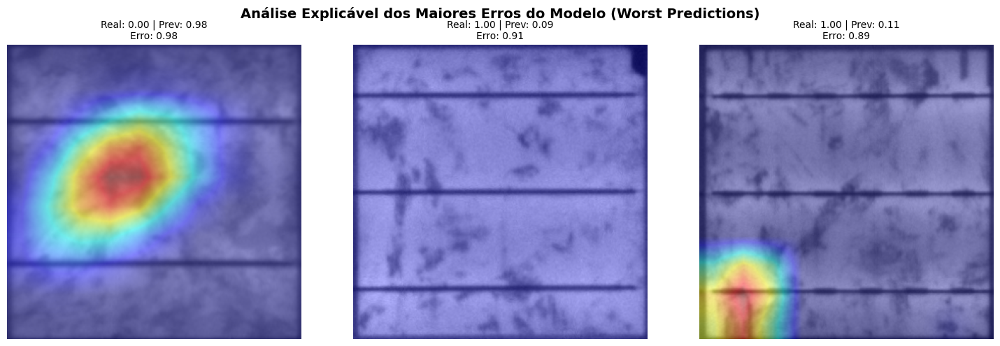

In [6]:
import numpy as np
import torch
import cv2
import matplotlib.pyplot as plt
import os

plots_path = os.path.join('../plots', 'maiores_erros.png')

# 1. Coletar previsões, erros e imagens do conjunto de teste
model.eval()
error_records = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs_dev = inputs.to(device)
        outputs = model(inputs_dev).cpu().numpy().flatten()
        targets_np = targets.numpy().flatten()
        
        for i in range(inputs.size(0)):
            true_val = targets_np[i]
            pred_val = outputs[i]
            abs_error = abs(true_val - pred_val)
            
            error_records.append({
                'image': inputs[i],
                'true': true_val,
                'pred': pred_val,
                'error': abs_error
            })

# Ordenar do maior erro para o menor
error_records = sorted(error_records, key=lambda x: x['error'], reverse=True)

print(f"Total de amostras avaliadas no teste: {len(error_records)}")
print(f"Maior erro absoluto encontrado: {error_records[0]['error']:.4f}")

# 2. Visualizar os 3 maiores erros do modelo com Grad-CAM
target_layer = model.layer4[-1]
grad_cam = GradCAM(model, target_layer)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for idx in range(3):
    record = error_records[idx]
    img_tensor = record['image'].unsqueeze(0).to(device)
    
    # Gerar Grad-CAM para a amostra com erro
    heatmap, pred_val = grad_cam.generate_heatmap(img_tensor)
    
    # Processar imagem original para exibição
    orig_img = record['image'][0].cpu().numpy()
    heatmap_resized = cv2.resize(heatmap, (300, 300))
    
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
    
    orig_rgb = np.stack([orig_img, orig_img, orig_img], axis=-1)
    superimposed_img = np.float32(orig_rgb) * 0.6 + (np.float32(heatmap_colored) / 255.0) * 0.4
    superimposed_img = superimposed_img / np.max(superimposed_img)
    
    # Plotar
    axes[idx].imshow(superimposed_img)
    axes[idx].set_title(f"Real: {record['true']:.2f} | Prev: {record['pred']:.2f}\nErro: {record['error']:.2f}", fontsize=10)
    axes[idx].axis('off')

plt.suptitle("Análise Explicável dos Maiores Erros do Modelo (Worst Predictions)", fontsize=14, fontweight='bold')
plt.savefig(plots_path, format='png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

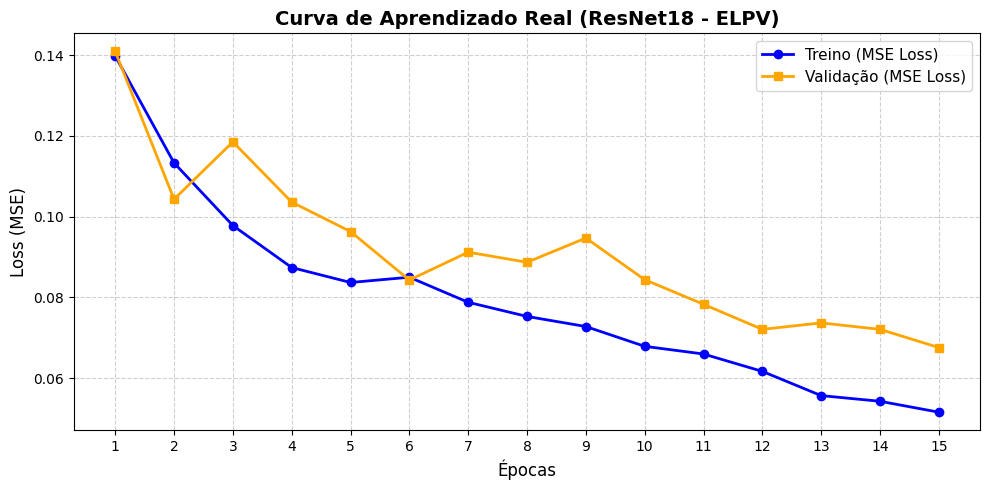

In [7]:
import matplotlib.pyplot as plt
import os

plots_path = os.path.join('../plots', 'curva_aprendizado_real.png')


# Histórico real extraído do treinamento anterior
history_train_loss = [
    0.1398, 0.1133, 0.0978, 0.0874, 0.0837, 
    0.0850, 0.0788, 0.0753, 0.0728, 0.0679, 
    0.0660, 0.0617, 0.0557, 0.0543, 0.0516
]

history_val_loss = [
    0.1409, 0.1043, 0.1185, 0.1036, 0.0963, 
    0.0843, 0.0912, 0.0887, 0.0947, 0.0844, 
    0.0783, 0.0721, 0.0737, 0.0721, 0.0676
]

# Plotando a curva de aprendizado real
plt.figure(figsize=(10, 5))

plt.plot(range(1, 16), history_train_loss, label='Treino (MSE Loss)', color='blue', marker='o', linewidth=2)
plt.plot(range(1, 16), history_val_loss, label='Validação (MSE Loss)', color='orange', marker='s', linewidth=2)

plt.title('Curva de Aprendizado Real (ResNet18 - ELPV)', fontsize=14, fontweight='bold')
plt.xlabel('Épocas', fontsize=12)
plt.ylabel('Loss (MSE)', fontsize=12)
plt.xticks(range(1, 16)) # Garante que apareçam todas as 15 épocas no eixo X
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

# Salva a imagem em alta resolução
plt.savefig(plots_path, format='png', dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()

Total de amostras avaliadas no teste: 394
Menor erro absoluto encontrado: 0.0000


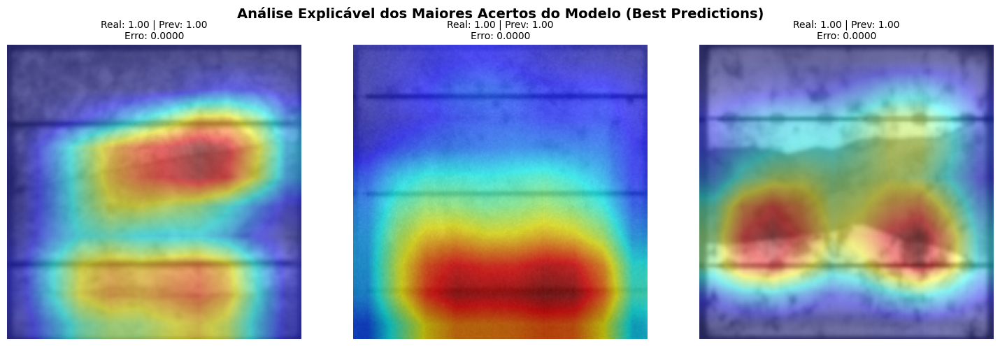

In [8]:
import numpy as np
import torch
import cv2
import matplotlib.pyplot as plt
import os

plots_path = os.path.join('../plots', 'melhores_acertos.png')

# 1. Coletar previsões, erros e imagens de todo o conjunto de teste
model.eval()
error_records = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs_dev = inputs.to(device)
        outputs = model(inputs_dev).cpu().numpy().flatten()
        targets_np = targets.numpy().flatten()
        
        for i in range(inputs.size(0)):
            true_val = targets_np[i]
            pred_val = outputs[i]
            abs_error = abs(true_val - pred_val)
            
            error_records.append({
                'image': inputs[i],
                'true': true_val,
                'pred': pred_val,
                'error': abs_error
            })

# Ordenar do menor erro para o maior (reverse=False)
error_records = sorted(error_records, key=lambda x: x['error'], reverse=False)

print(f"Total de amostras avaliadas no teste: {len(error_records)}")
print(f"Menor erro absoluto encontrado: {error_records[0]['error']:.4f}")

# 2. Visualizar os 3 maiores acertos do modelo com Grad-CAM
target_layer = model.layer4[-1]
grad_cam = GradCAM(model, target_layer)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for idx in range(3):
    record = error_records[idx]
    img_tensor = record['image'].unsqueeze(0).to(device)
    
    # Gerar Grad-CAM para a amostra com menor erro
    heatmap, pred_val = grad_cam.generate_heatmap(img_tensor)
    
    # Processar imagem original para exibição
    orig_img = record['image'][0].cpu().numpy()
    heatmap_resized = cv2.resize(heatmap, (300, 300))
    
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
    
    orig_rgb = np.stack([orig_img, orig_img, orig_img], axis=-1)
    superimposed_img = np.float32(orig_rgb) * 0.6 + (np.float32(heatmap_colored) / 255.0) * 0.4
    superimposed_img = superimposed_img / np.max(superimposed_img)
    
    # Plotar
    axes[idx].imshow(superimposed_img)
    axes[idx].set_title(f"Real: {record['true']:.2f} | Prev: {record['pred']:.2f}\nErro: {record['error']:.4f}", fontsize=10)
    axes[idx].axis('off')

plt.suptitle("Análise Explicável dos Maiores Acertos do Modelo (Best Predictions)", fontsize=14, fontweight='bold')
plt.savefig(plots_path, format='png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

Total de amostras defeituosas rotuladas corretamente encontradas: 99
Exibindo as 20 melhores predições...


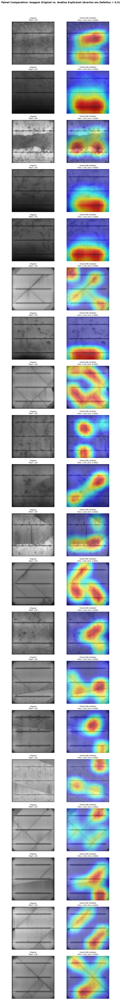

In [9]:
import numpy as np
import torch
import cv2
import matplotlib.pyplot as plt
import os

plots_path = os.path.join('../plots', 'acertos_defeitos_gradcam.png')

# 1. Coletar amostras do conjunto de teste que atendem ao critério:
# Rótulo real >= 0.5 (defeituoso) e Predição >= 0.5 (rotulado corretamente como defeituoso)
model.eval()
correct_defective_records = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs_dev = inputs.to(device)
        outputs = model(inputs_dev).cpu().numpy().flatten()
        targets_np = targets.numpy().flatten()
        
        for i in range(inputs.size(0)):
            true_val = targets_np[i]
            pred_val = outputs[i]
            
            # Critério solicitado: Real >= 0.5 e Predito >= 0.5
            if true_val >= 0.5 and pred_val >= 0.5:
                abs_error = abs(true_val - pred_val)
                correct_defective_records.append({
                    'image': inputs[i],
                    'true': true_val,
                    'pred': pred_val,
                    'error': abs_error
                })

# Ordenar do menor erro para o maior (as previsões mais certeiras)
correct_defective_records = sorted(correct_defective_records, key=lambda x: x['error'], reverse=False)

# Limitar a no máximo 20 imagens (ou menos se o dataset de teste tiver menos que isso)
num_samples = min(20, len(correct_defective_records))
print(f"Total de amostras defeituosas rotuladas corretamente encontradas: {len(correct_defective_records)}")
print(f"Exibindo as {num_samples} melhores predições...")

# 2. Instanciar o Grad-CAM
target_layer = model.layer4[-1]
grad_cam = GradCAM(model, target_layer)

# 3. Plotar a grade comparativa (Original vs Grad-CAM)
fig, axes = plt.subplots(num_samples, 2, figsize=(10, 4 * num_samples))

# Garantir que axes seja bidimensional mesmo se num_samples for 1
if num_samples == 1:
    axes = np.expand_dims(axes, axis=0)

for idx in range(num_samples):
    record = correct_defective_records[idx]
    img_tensor = record['image'].unsqueeze(0).to(device)
    
    # Gerar o Grad-CAM
    heatmap, pred_val = grad_cam.generate_heatmap(img_tensor)
    
    # Processar a imagem original (1 canal)
    orig_img = record['image'][0].cpu().numpy()
    h_orig, w_orig = orig_img.shape
    
    # Redimensionar e colorir o heatmap
    heatmap_resized = cv2.resize(heatmap, (w_orig, h_orig))
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
    
    # Imagem original em 3 canais RGB
    orig_rgb = np.stack([orig_img, orig_img, orig_img], axis=-1)
    
    # Mistura ponderada (Overlay)
    superimposed_img = np.float32(orig_rgb) * 0.6 + (np.float32(heatmap_colored) / 255.0) * 0.4
    superimposed_img = superimposed_img / np.max(superimposed_img)
    
    # Coluna 1: Imagem Original
    axes[idx, 0].imshow(orig_rgb)
    axes[idx, 0].set_title(f"Original\nReal: {record['true']:.2f}", fontsize=10)
    axes[idx, 0].axis('off')
    
    # Coluna 2: Análise Explicável (Grad-CAM)
    axes[idx, 1].imshow(superimposed_img)
    axes[idx, 1].set_title(f"Grad-CAM (Análise)\nPrev: {record['pred']:.2f} | Erro: {record['error']:.4f}", fontsize=10)
    axes[idx, 1].axis('off')

plt.suptitle("Painel Comparativo: Imagem Original vs. Análise Explicável (Acertos em Defeitos > 0.5)", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(plots_path, format='png', dpi=300, bbox_inches='tight')
plt.show()

Total de amostras saudáveis rotuladas incorretamente encontradas: 14
Exibindo as 14 piores predições (Falsos Positivos)...


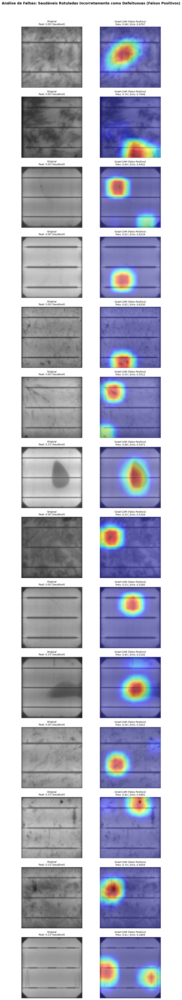

In [10]:
import numpy as np
import torch
import cv2
import matplotlib.pyplot as plt
import os

plots_path = os.path.join('../plots', 'erros_falsos_positivos.png')

# 1. Coletar amostras do conjunto de teste que atendem ao critério:
# Rótulo real < 0.5 (saudável) e Predição >= 0.5 (falso positivo)
model.eval()
false_positive_records = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs_dev = inputs.to(device)
        outputs = model(inputs_dev).cpu().numpy().flatten()
        targets_np = targets.numpy().flatten()
        
        for i in range(inputs.size(0)):
            true_val = targets_np[i]
            pred_val = outputs[i]
            
            # Critério solicitado: Real < 0.5 (Saudável) e Predito >= 0.5 (Falso Positivo)
            if true_val < 0.5 and pred_val >= 0.5:
                abs_error = abs(true_val - pred_val)
                false_positive_records.append({
                    'image': inputs[i],
                    'true': true_val,
                    'pred': pred_val,
                    'error': abs_error
                })

# Ordenar do maior erro/confiança do erro para o menor
false_positive_records = sorted(false_positive_records, key=lambda x: x['error'], reverse=True)

# Limitar a no máximo 20 imagens (ou menos se o dataset tiver menos que isso)
num_samples = min(20, len(false_positive_records))
print(f"Total de amostras saudáveis rotuladas incorretamente encontradas: {len(false_positive_records)}")
print(f"Exibindo as {num_samples} piores predições (Falsos Positivos)...")

if num_samples > 0:
    # 2. Instanciar o Grad-CAM (garantindo que o target_layer está correto)
    target_layer = model.layer4[-1]
    grad_cam = GradCAM(model, target_layer)

    # 3. Plotar a grade comparativa (Original vs Grad-CAM)
    fig, axes = plt.subplots(num_samples, 2, figsize=(10, 4 * num_samples))

    if num_samples == 1:
        axes = np.expand_dims(axes, axis=0)

    for idx in range(num_samples):
        record = false_positive_records[idx]
        img_tensor = record['image'].unsqueeze(0).to(device)
        
        # Gerar o Grad-CAM
        heatmap, pred_val = grad_cam.generate_heatmap(img_tensor)
        
        # Processar a imagem original (1 canal)
        orig_img = record['image'][0].cpu().numpy()
        h_orig, w_orig = orig_img.shape
        
        # Redimensionar e colorir o heatmap
        heatmap_resized = cv2.resize(heatmap, (w_orig, h_orig))
        heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
        heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
        
        # Imagem original em 3 canais RGB
        orig_rgb = np.stack([orig_img, orig_img, orig_img], axis=-1)
        
        # Mistura ponderada (Overlay)
        superimposed_img = np.float32(orig_rgb) * 0.6 + (np.float32(heatmap_colored) / 255.0) * 0.4
        superimposed_img = superimposed_img / np.max(superimposed_img)
        
        # Coluna 1: Imagem Original
        axes[idx, 0].imshow(orig_rgb)
        axes[idx, 0].set_title(f"Original\nReal: {record['true']:.2f} (Saudável)", fontsize=10)
        axes[idx, 0].axis('off')
        
        # Coluna 2: Análise Explicável (Grad-CAM)
        axes[idx, 1].imshow(superimposed_img)
        axes[idx, 1].set_title(f"Grad-CAM (Falso Positivo)\nPrev: {record['pred']:.2f} | Erro: {record['error']:.4f}", fontsize=10)
        axes[idx, 1].axis('off')

    plt.suptitle("Análise de Falhas: Saudáveis Rotuladas Incorretamente como Defeituosas (Falsos Positivos)", fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.savefig(plots_path, format='png', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print("Nenhuma amostra encontrada com este critério exato no conjunto de teste atual.")